# Benchmark Structure Prediction Methods

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences['fold'] = sequences['fold'].astype(str)

## Antigen Specificity

In [ ]:
def calculate_performance(pae_scores: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = 1 - roc_auc_score(labels, pae_scores)
    roc_auc01 = 1 - roc_auc_score(labels, pae_scores, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, pae_scores)
    pr_auc = 1 - auc(recall, precision)

    return pd.Series({'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc})


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [ ]:
af3_confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
af3_confidence_scores['model'] = 'AlphaFold3'

In [5]:
af3_confidence_scores['top_rank'] = False
af3_confidence_scores.loc[af3_confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [6]:
boltz_confidence_scores = pd.read_csv('../data/interim/confidence_scores_boltz_af3_tcrmodel2_1500.csv')
boltz_confidence_scores['model'] = 'Boltz-2'

In [7]:
boltz_confidence_scores['top_rank'] = False
boltz_confidence_scores.loc[boltz_confidence_scores.groupby('name')['confidence_score'].idxmax(), 'top_rank'] = True

In [8]:
chai_confidence_scores = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_1500.csv')
chai_confidence_scores['model'] = 'Chai-1'

In [9]:
chai_confidence_scores['top_rank'] = False
chai_confidence_scores.loc[chai_confidence_scores.groupby('name')['aggregate_score'].idxmax(), 'top_rank'] = True

In [10]:
af2_confidence_scores = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_1500.csv')
af2_confidence_scores['model'] = 'AlphaFold2'

In [11]:
af2_confidence_scores['top_rank'] = False
af2_confidence_scores.loc[af2_confidence_scores.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'] = True

In [12]:
confidence_scores = pd.concat(
    [af3_confidence_scores, boltz_confidence_scores, chai_confidence_scores, af2_confidence_scores]
).reset_index(drop=True)

In [13]:
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

### Overall

In [14]:
metric_scores = confidence_scores.groupby('model').apply(
    lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False
)

metric_scores_top_rank = (
    confidence_scores.query('top_rank')
    .groupby('model')
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
)

print('All')
ipy_display.display(metric_scores)

print()

print('Top Ranked')
ipy_display.display(metric_scores_top_rank)

All


,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold2,0.550476,0.507572,0.535067
AlphaFold3,0.600320,0.502683,0.551116
Boltz-2,0.562251,0.513222,0.549348
Chai-1,0.612472,0.509811,0.568085



Top Ranked


,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold2,0.541764,0.499949,0.516920
AlphaFold3,0.601319,0.504065,0.551730
Boltz-2,0.549703,0.517361,0.547792
Chai-1,0.610727,0.510232,0.566772


### Bootstrap

In [15]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500

names = confidence_scores['name'].unique()
rng = np.random.default_rng(123)

samples_metric_scores = []
samples_metric_scores_top_rank = []
for sample_num in range(1, NUM_SAMPLES + 1):
    sample_names = rng.choice(names, SAMPLE_SIZE)

    sample = confidence_scores[confidence_scores['name'].isin(sample_names)]

    sample_metric_scores = (
        sample.groupby('model')
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )
    sample_metric_scores['sample_num'] = sample_num

    samples_metric_scores.append(sample_metric_scores)

    sample_metric_scores_top_rank = (
        sample.query('top_rank')
        .groupby('model')
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )

    sample_metric_scores_top_rank['sample_num'] = sample_num

    samples_metric_scores_top_rank.append(sample_metric_scores_top_rank)

samples_metric_scores = pd.concat(samples_metric_scores).reset_index(drop=True)
samples_metric_scores_top_rank = pd.concat(samples_metric_scores_top_rank).reset_index(drop=True)

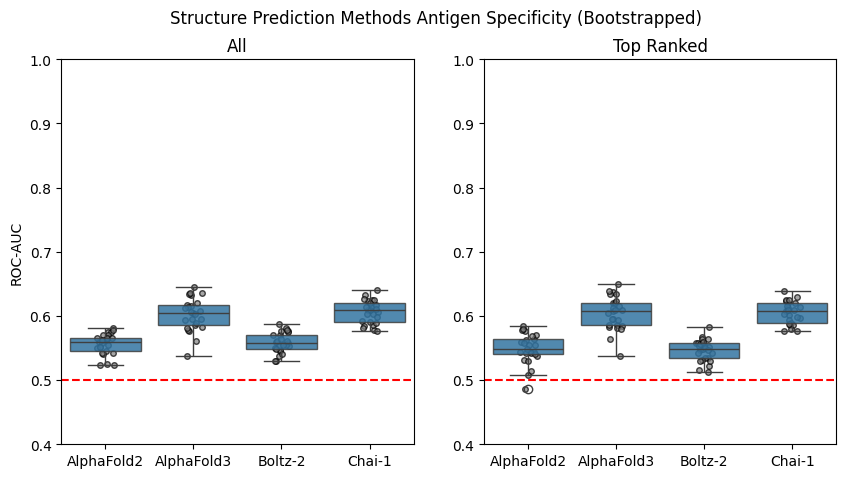

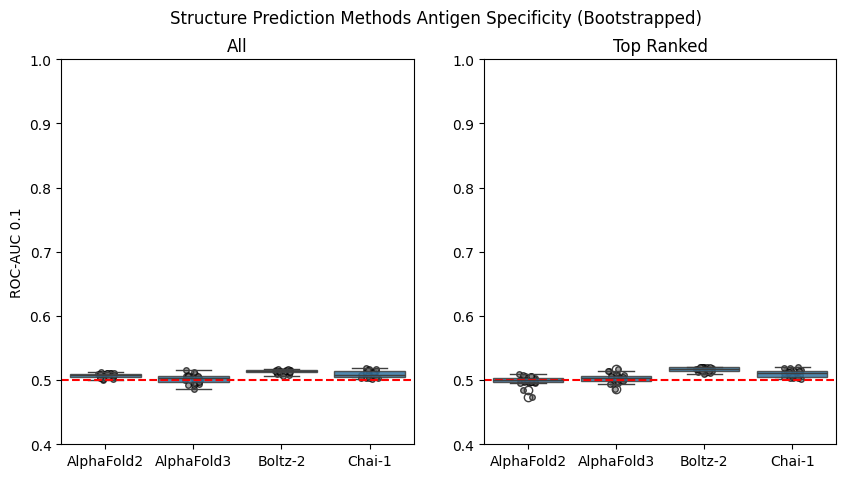

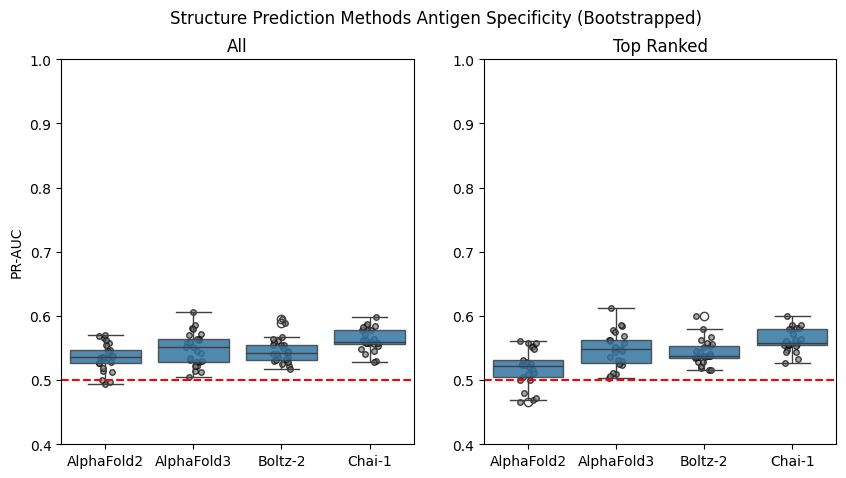

In [16]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    fig.suptitle('Structure Prediction Methods Antigen Specificity (Bootstrapped)')

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True)
    ):
        sns.stripplot(
            data,
            x='model',
            y=metric_name,
            color='grey',
            zorder=1,
            marker='o',
            size=4,
            edgecolor='black',
            linewidth=1,
            alpha=0.70,
            ax=ax,
        )
        sns.boxplot(data, x='model', y=metric_name, boxprops={'alpha': 0.85}, ax=ax)

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.4, 1.0)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.savefig(f'../report/figures/method_benchmark_specificity_bootstrap_{metric_name}.svg')
    plt.show()

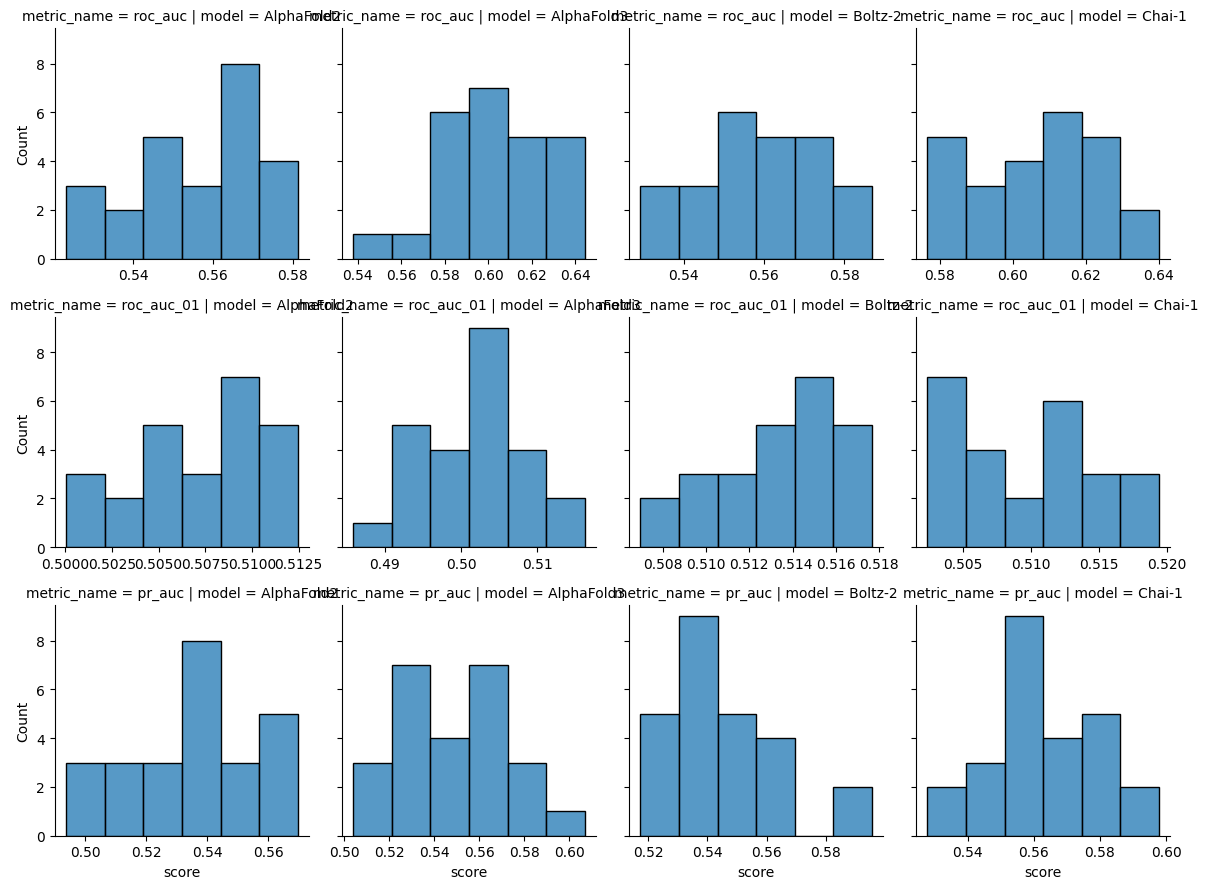

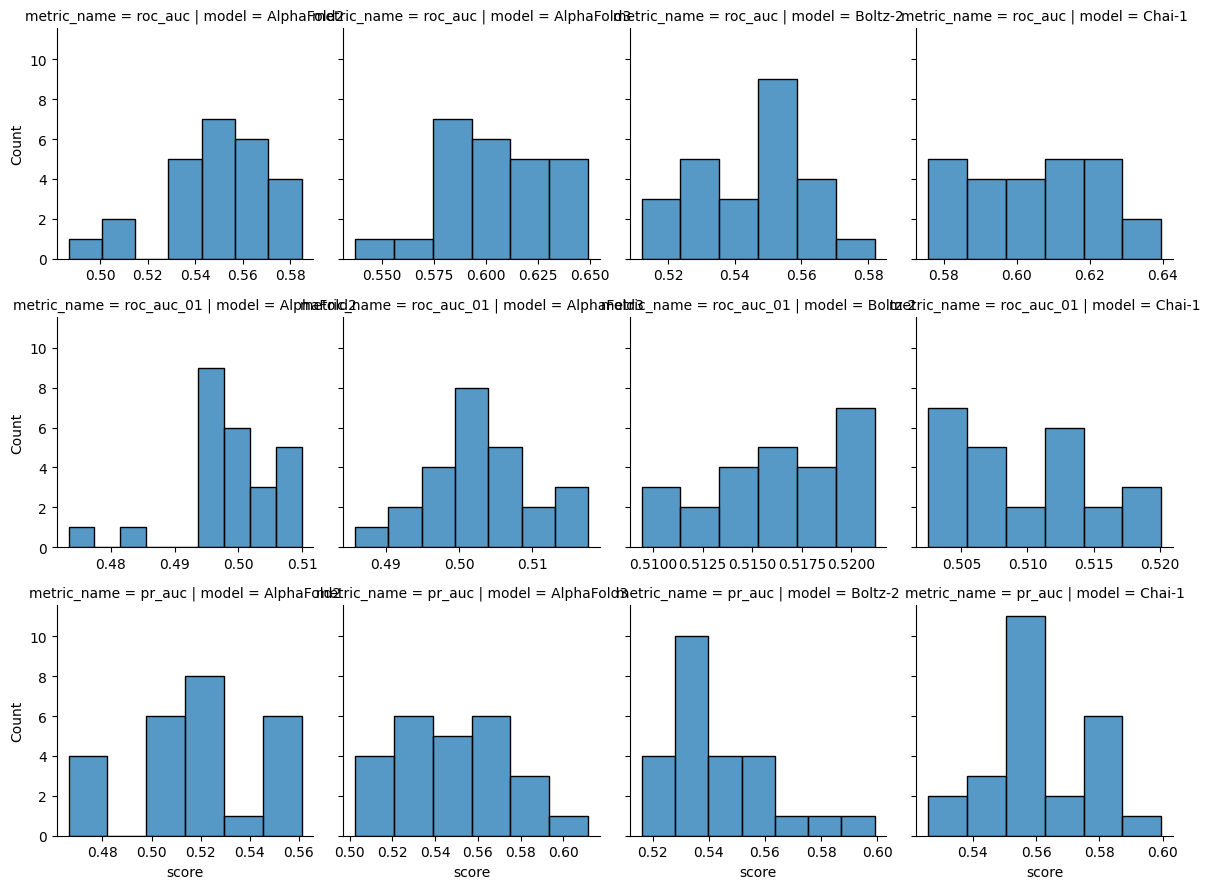

In [17]:
sns.FacetGrid(
    samples_metric_scores.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    samples_metric_scores_top_rank.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [18]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.anova(data, dv=metric_name, between='model')

    groups = list(data.groupby('model')[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [19]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_normal(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)
        print()

ROC-AUC
All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,49.229475,2.352327e-19,0.606054


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-7.585325,9.372786e-10,True
1,AlphaFold2,Boltz-2,-0.534188,5.956769e-01,False
2,AlphaFold2,Chai-1,-10.258394,1.091441e-13,True
3,AlphaFold3,Boltz-2,7.286173,2.681237e-09,True
4,AlphaFold3,Chai-1,-0.618510,5.391633e-01,False
5,Boltz-2,Chai-1,-9.978345,2.719076e-13,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,58.949637,1.070099e-21,0.648157


...

,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,7.096566,0.000234,0.181514


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-2.053186,0.045526,False
1,AlphaFold2,Boltz-2,-1.912543,0.061784,False
2,AlphaFold2,Chai-1,-4.999415,0.000008,True
3,AlphaFold3,Boltz-2,0.441240,0.661021,False
4,AlphaFold3,Chai-1,-2.182594,0.033990,False
5,Boltz-2,Chai-1,-3.193491,0.002483,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,96,14.341549,8.549585e-08,0.309475


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-3.655389,6.356502e-04,True
1,AlphaFold2,Boltz-2,-3.612714,7.235546e-04,True
2,AlphaFold2,Chai-1,-6.561447,3.461497e-08,True
3,AlphaFold3,Boltz-2,0.612860,5.428622e-01,False
4,AlphaFold3,Chai-1,-2.183297,3.393521e-02,False
5,Boltz-2,Chai-1,-3.516974,9.650614e-04,True


### By Fold

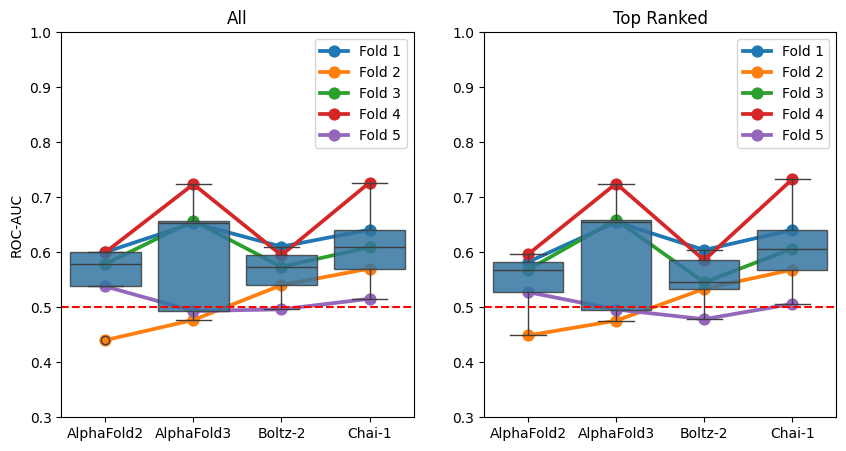

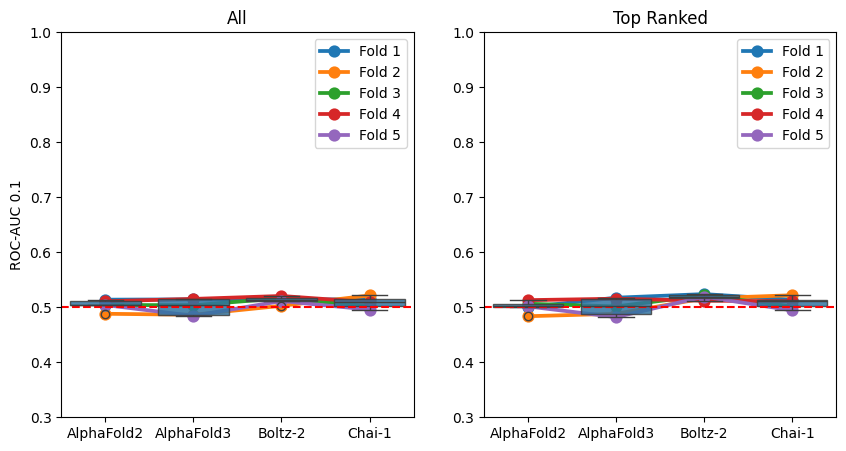

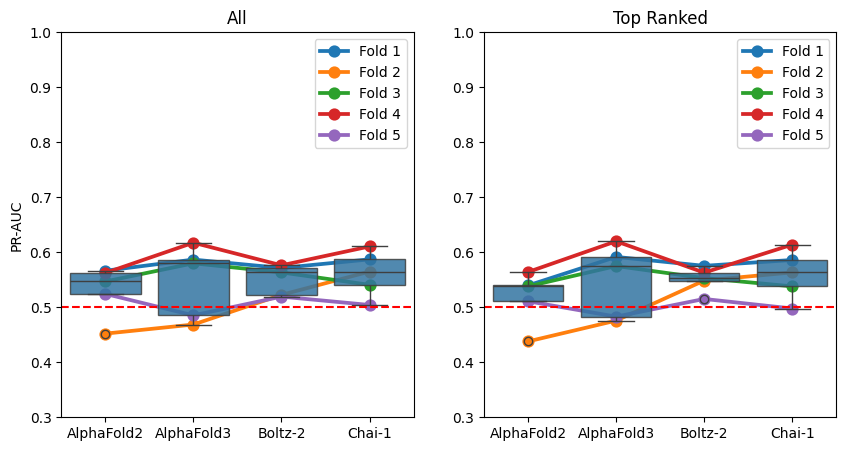

In [20]:
roc_aucs_by_fold = (
    confidence_scores.groupby(['model', 'fold'])
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)

roc_aucs_by_fold_top_rank = (
    confidence_scores.query('top_rank')
    .groupby(['model', 'fold'])
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)


for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True)
    ):
        sns.pointplot(data, x='model', y=metric_name, hue='fold', ax=ax)
        sns.boxplot(data, x='model', y=metric_name, boxprops={'alpha': 0.85}, ax=ax)

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.3, 1.0)

        handles, labels = ax.get_legend_handles_labels()
        new_labels = [f'Fold {label}' for label in labels]
        ax.legend(handles, new_labels)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.savefig(f'../report/figures/method_benchmark_specificity_fold_{metric_name}.svg')
    plt.show()

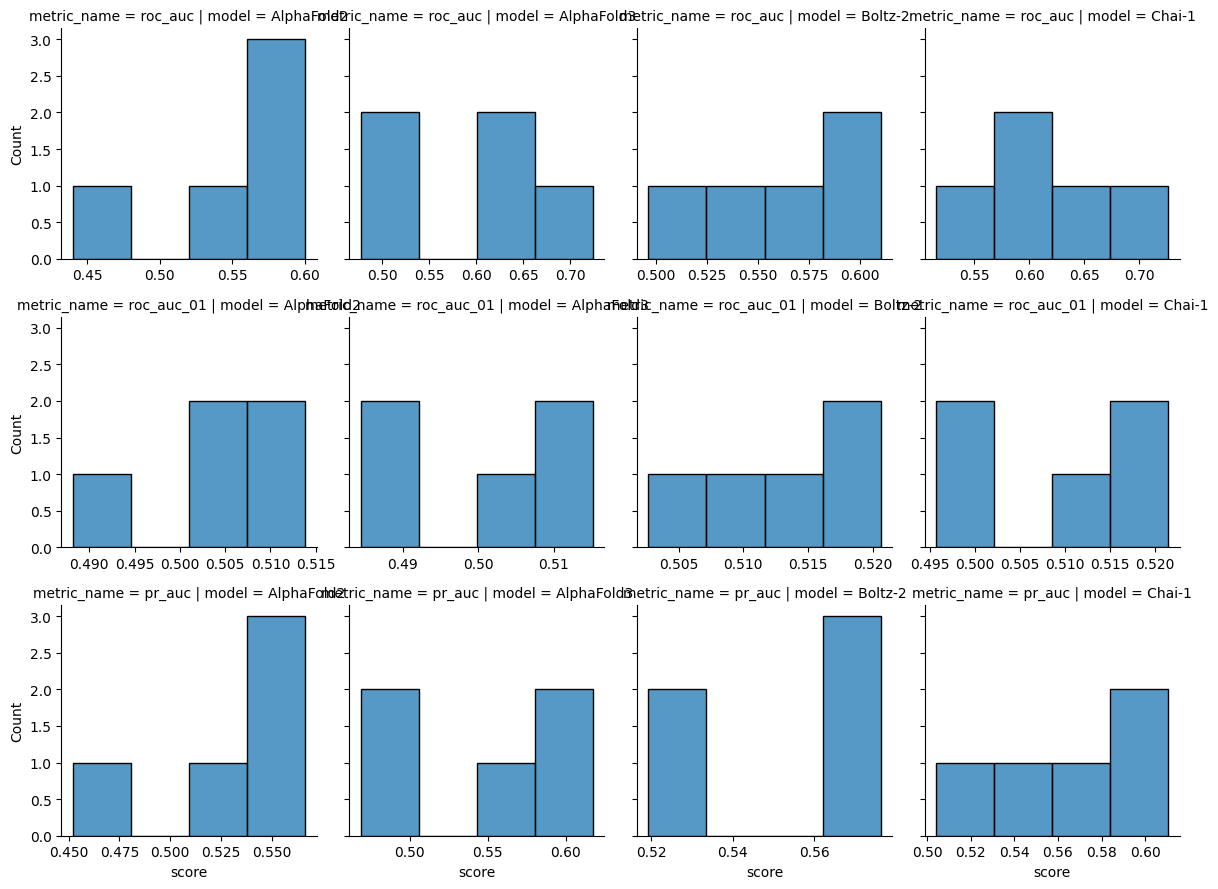

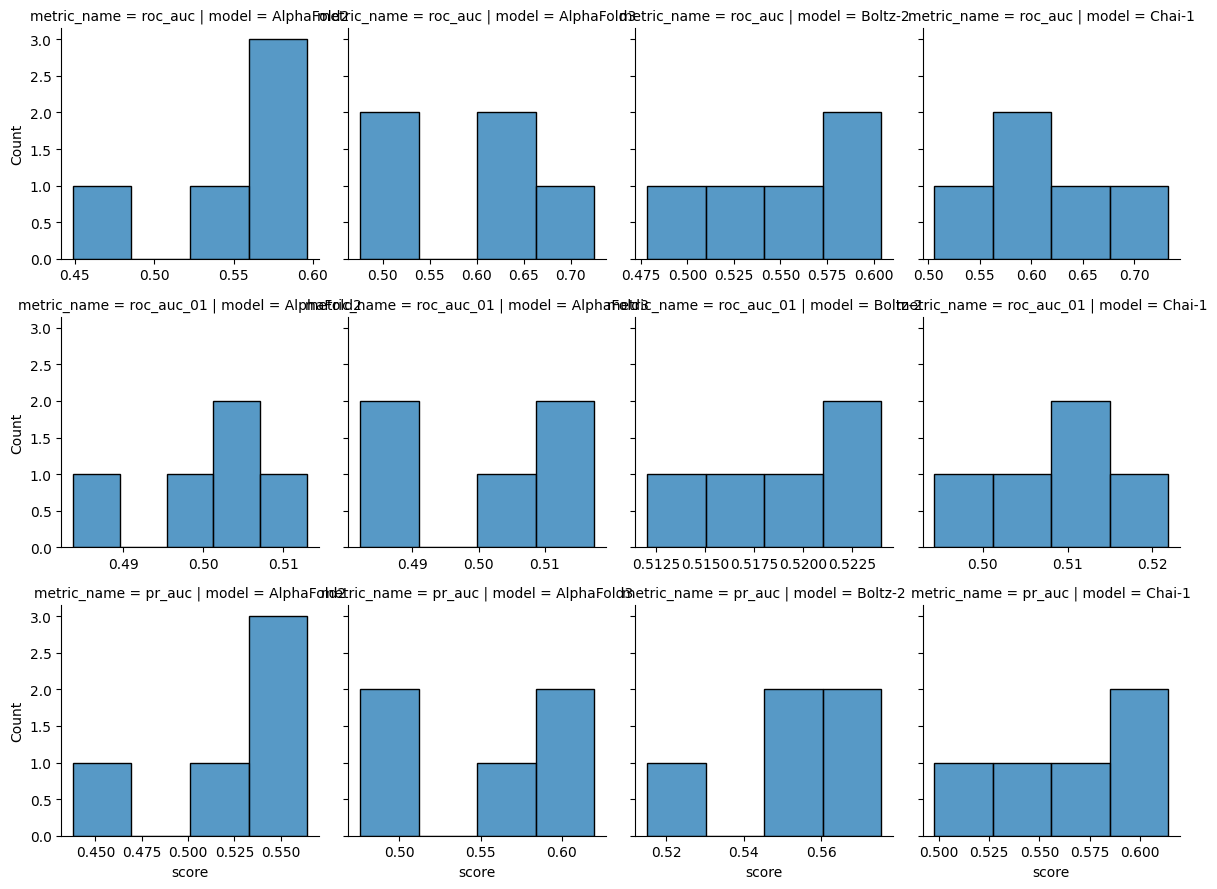

In [21]:
sns.FacetGrid(
    roc_aucs_by_fold.melt(
        id_vars=['model', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    roc_aucs_by_fold_top_rank.melt(
        id_vars=['model', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [22]:
def statistics_non_parametric(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.friedman(data, dv=metric_name, within='model', subject='fold', method='f')

    groups = list(data.set_index('fold').groupby('model')[metric_name])
    groups = [(group_name, group.sort_index()) for group_name, group in groups]

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.wilcoxon(group1, group2, alternative='greater')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [23]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_non_parametric(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)

        print()

    print()

ROC-AUC
All


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.328,2.6,10.4,1.952381,0.186081


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,2.0,0.93750,False
1,AlphaFold2,Boltz-2,7.0,0.59375,False
2,AlphaFold2,Chai-1,1.0,0.96875,False
3,AlphaFold3,Boltz-2,11.0,0.21875,False
4,AlphaFold3,Chai-1,6.0,0.68750,False
5,Boltz-2,Chai-1,0.0,1.00000,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.424,2.6,10.4,2.944444,0.088004


...

,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.136,2.6,10.4,0.62963,0.590964


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,4.0,0.84375,False
1,AlphaFold2,Boltz-2,1.0,0.96875,False
2,AlphaFold2,Chai-1,3.0,0.90625,False
3,AlphaFold3,Boltz-2,7.0,0.59375,False
4,AlphaFold3,Chai-1,6.0,0.68750,False
5,Boltz-2,Chai-1,4.0,0.84375,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.232,2.6,10.4,1.208333,0.349106


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,1.0,0.96875,False
1,AlphaFold2,Boltz-2,1.0,0.96875,False
2,AlphaFold2,Chai-1,2.0,0.93750,False
3,AlphaFold3,Boltz-2,7.0,0.59375,False
4,AlphaFold3,Chai-1,7.0,0.59375,False
5,Boltz-2,Chai-1,7.0,0.59375,False


## Structure Quality

In [24]:
af3_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_benchmark.csv')

af3_confidence_scores_benchmark['top_rank'] = False
af3_confidence_scores_benchmark.loc[
    af3_confidence_scores_benchmark.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

af3_dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_benchmark.csv')
af3_dockq_scores['model'] = 'AlphaFold3'

af3_dockq_scores = af3_dockq_scores.merge(af3_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [25]:
boltz_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_boltz_af3_tcrmodel2_benchmark.csv')

boltz_confidence_scores_benchmark['top_rank'] = False
boltz_confidence_scores_benchmark.loc[
    boltz_confidence_scores_benchmark.groupby('name')['confidence_score'].idxmax(), 'top_rank'
] = True

boltz_dockq_scores = pd.read_csv('../data/processed/predicted_boltz_af3_tcrmodel2_dockq_benchmark.csv')
boltz_dockq_scores['model'] = 'Boltz-2'

boltz_dockq_scores = boltz_dockq_scores.merge(
    boltz_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

In [26]:
BOLTZ2_TRAINING_CUTOFF = '2023-06-01'

stcrdab_summary = pd.read_csv('../data/external/stcrdab/db_summary.dat', sep='\t')

stcrdab_summary['date'] = pd.to_datetime(stcrdab_summary['date'], format=r'%m/%d/%y')
stcrdab_summary['chains'] = (
    stcrdab_summary[['Achain', 'Bchain', 'antigen_chain', 'mhc_chain1', 'mhc_chain2']]
    .fillna('')
    .apply(lambda row: ''.join(row), axis=1)
)

boltz_dockq_scores[['pdb', 'chains']] = boltz_dockq_scores['name'].str.split('_').apply(pd.Series)
boltz_dockq_scores_with_dates = boltz_dockq_scores.merge(stcrdab_summary, how='left', on=['pdb', 'chains'])

boltz_dockq_scores = boltz_dockq_scores[boltz_dockq_scores_with_dates['date'] > BOLTZ2_TRAINING_CUTOFF]

In [27]:
boltz_dockq_scores['name'].unique()

array(['8shi_IJFDE', '8i5c_DECAB', '8i5d_ABPHL'], dtype=object)

In [28]:
chai_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_benchmark.csv')

chai_confidence_scores_benchmark['top_rank'] = False
chai_confidence_scores_benchmark.loc[
    chai_confidence_scores_benchmark.groupby('name')['aggregate_score'].idxmax(), 'top_rank'
] = True

chai_dockq_scores = pd.read_csv('../data/processed/predicted_chai_af3_tcrmodel2_dockq_benchmark.csv')
chai_dockq_scores['model'] = 'Chai-1'

chai_dockq_scores = chai_dockq_scores.merge(
    chai_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

In [29]:
af2_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_benchmark.csv')

af2_confidence_scores_benchmark['top_rank'] = False
af2_confidence_scores_benchmark.loc[
    af2_confidence_scores_benchmark.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'
] = True

af2_dockq_scores = pd.read_csv('../data/processed/predicted_af2_af3_tcrmodel2_dockq_benchmark.csv')
af2_dockq_scores['model'] = 'AlphaFold2'

af2_dockq_scores = af2_dockq_scores.merge(af2_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [30]:
dockq_scores = pd.concat([af3_dockq_scores, boltz_dockq_scores, chai_dockq_scores, af2_dockq_scores])

In [31]:
dockq_scores.loc[dockq_scores['DockQ'].isna(), 'DockQ'] = 0.0

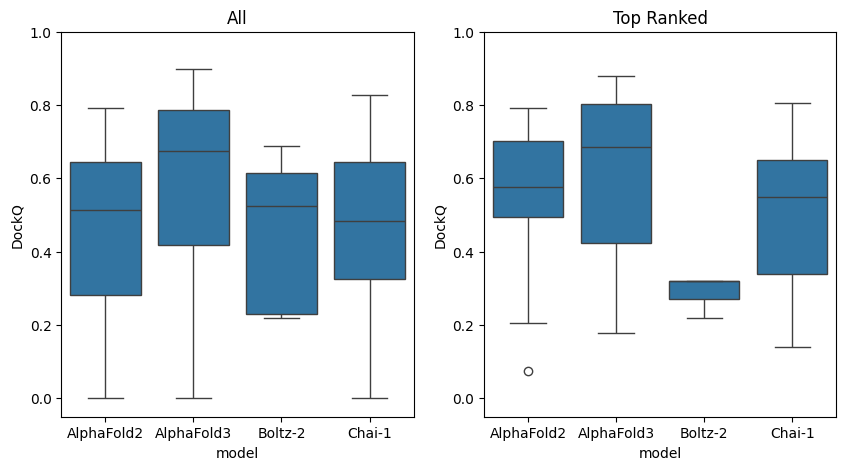

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)

    sns.boxplot(data.sort_values('model'), x='model', y='DockQ', ax=ax)

    ax.set_ylim(-0.05, 1.0)

plt.savefig('../report/figures/method_benchmark_dockq_boxplot.svg')
plt.show()

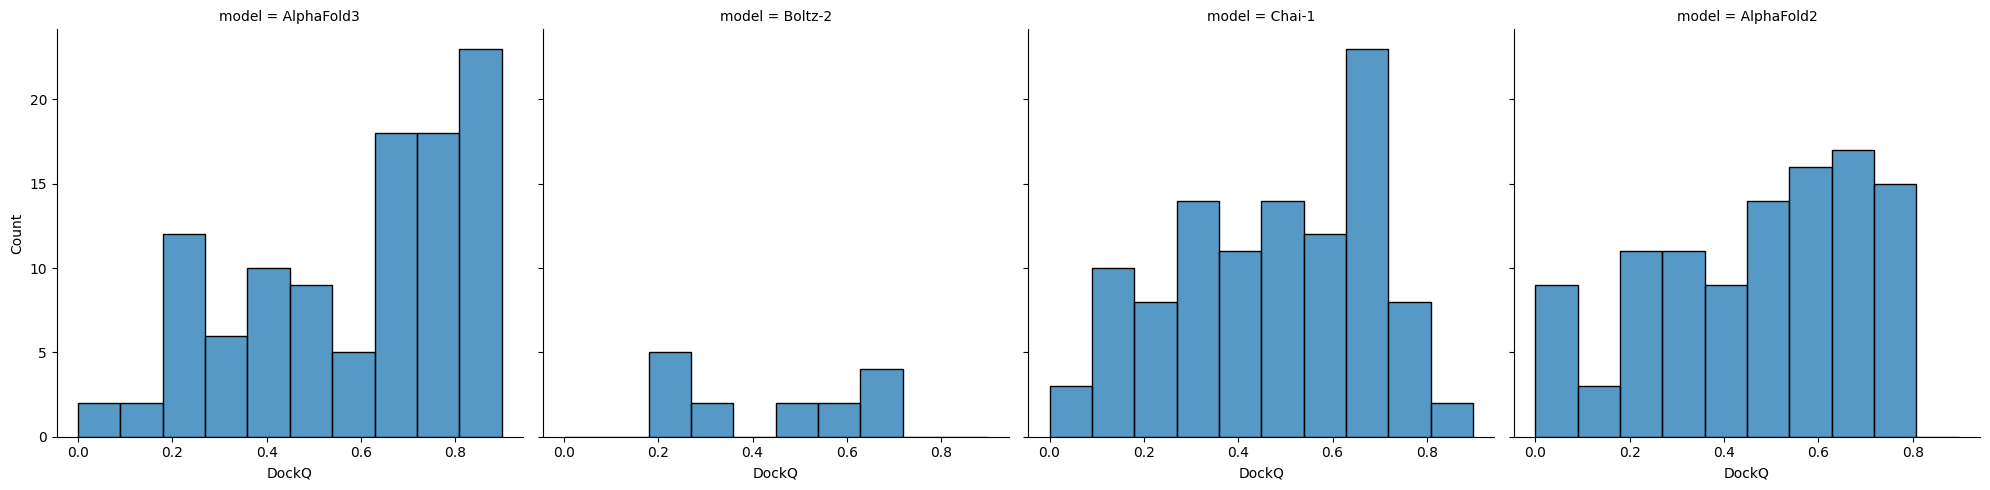

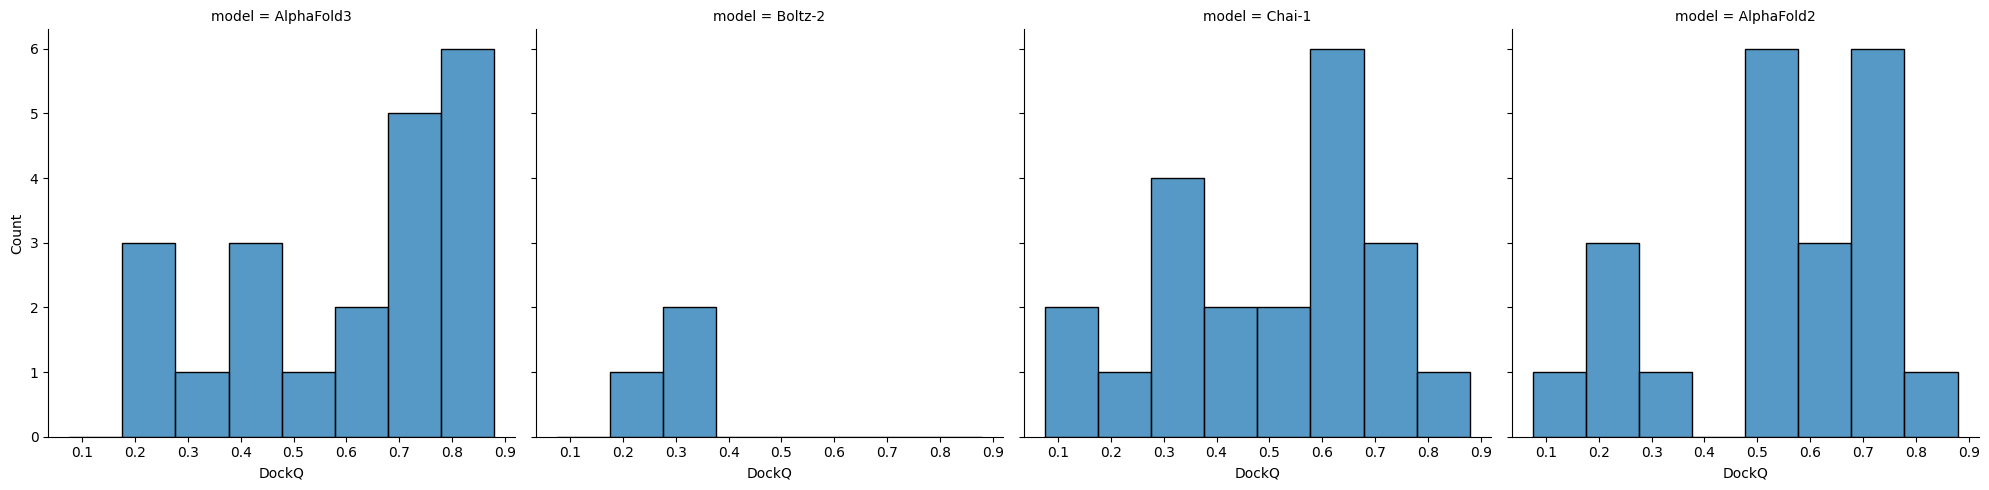

In [33]:
sns.displot(dockq_scores, col='model', x='DockQ', kind='hist')
sns.displot(dockq_scores.query('top_rank'), col='model', x='DockQ', kind='hist')

In [34]:
for title, data in zip(('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    print(title)

    ipy_display.display(pg.anova(data, dv='DockQ', between='model'))

    groups = list(data.groupby('model')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,326,7.607019,0.000062,0.065423


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-3.775482,0.000208,True
1,AlphaFold2,Boltz-2,0.526053,0.599839,False
2,AlphaFold2,Chai-1,0.197463,0.843658,False
3,AlphaFold3,Boltz-2,2.335857,0.021187,False
4,AlphaFold3,Chai-1,4.039339,0.000075,True
5,Boltz-2,Chai-1,-0.445618,0.656690,False



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,3,62,2.187469,0.098436,0.095714


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-0.825443,0.414016,False
1,AlphaFold2,Boltz-2,2.067647,0.050634,False
2,AlphaFold2,Chai-1,0.646581,0.521596,False
3,AlphaFold3,Boltz-2,2.260430,0.034031,False
4,AlphaFold3,Chai-1,1.446921,0.155711,False
5,Boltz-2,Chai-1,-1.798887,0.085771,False


In [35]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [36]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [37]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    capri_classification = dockq_scores.groupby('model')['capri_classification'].value_counts(normalize=True) * 100
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='model', columns='capri_classification', values='percent'
    )

    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    plot_ax = capri_classification.reindex(columns=order, fill_value=0).plot(
        kind='bar',
        stacked=True,
        color=[colours[col_name] for col_name in order],
        width=0.8,
        edgecolor='none',
        legend=False,
        ax=ax,
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')

    return plot_ax

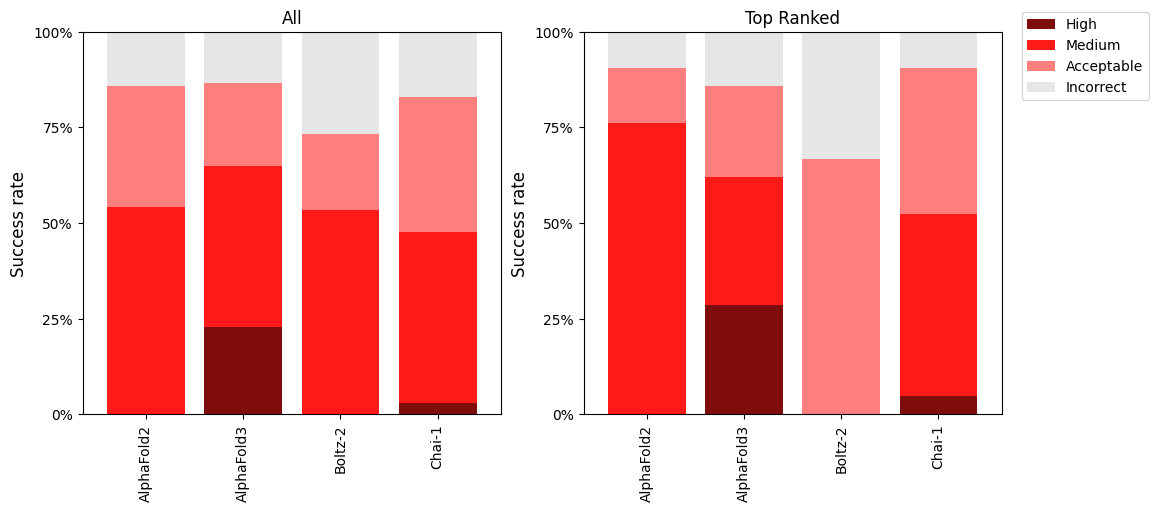

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)
    plot_capri_classification(data, ax=ax)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.savefig('../report/figures/method_benchmark_dockq_capri.svg', bbox_inches='tight')
plt.show()